In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, recall_score, precision_score, f1_score

sns.set_theme(style="whitegrid")
BLUE, GRAY = "#1F3A5F", "#9AA5B1"

data = pd.read_csv("../data/processed/model_ready_data.csv")
X = data.drop(columns=["Attrition"])
y = data["Attrition"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

best_model = joblib.load("../models/best_model.pkl")
final = pd.read_csv("../data/final/final_attrition_data.csv")
print(X.shape, final.shape)

KeyboardInterrupt: 

In [2]:
base = best_model.predict_proba(X)[:, 1]
high = (final["RiskLevel"] == "High").values

def s_overtime(d):
    return d.assign(OverTime=0)

def s_travel(d):
    return d.assign(BusinessTravel_Travel_Frequently=0)

def s_satisfaction(d):
    return d.assign(
        EnvironmentSatisfaction=(d["EnvironmentSatisfaction"] + 1).clip(upper=4),
        JobSatisfaction=(d["JobSatisfaction"] + 1).clip(upper=4))

scenarios = {
    "Remove overtime": [s_overtime],
    "Reduce frequent travel": [s_travel],
    "Improve satisfaction (+1)": [s_satisfaction],
    "All three combined": [s_overtime, s_travel, s_satisfaction],
}

def simulate(fns):
    X_new = X.copy()
    sub = X.loc[high].copy()
    for f in fns:
        sub = f(sub)
    X_new.loc[high] = sub
    return best_model.predict_proba(X_new)[:, 1]

dept = final["Department"].values
rows = []
for name, fns in scenarios.items():
    new = simulate(fns)
    row = {"Scenario": name}
    for d in sorted(set(dept)):
        m = dept == d
        row[d] = (1 - new[m].sum() / base[m].sum()) * 100
    row["Overall"] = (1 - new.sum() / base.sum()) * 100
    rows.append(row)

impact = pd.DataFrame(rows).set_index("Scenario").round(1)
impact.to_csv("../outputs/tables/impact_simulation.csv")
impact

,Human Resources,Research & Development,Sales,Overall
Scenario,,,,
Remove overtime,7.3,14.1,11.1,12.6
Reduce frequent travel,9.7,7.7,4.9,6.7
Improve satisfaction (+1),9.2,7.0,7.1,7.1
All three combined,26.9,27.5,24.3,26.2


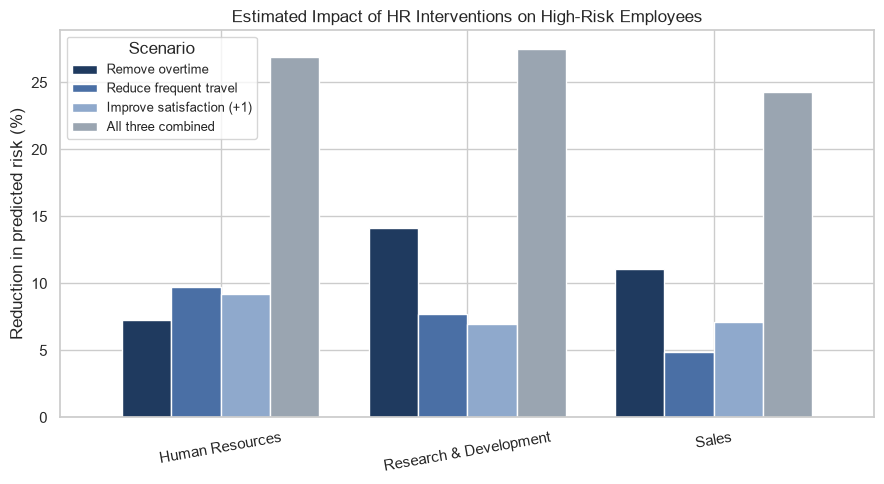

In [3]:
plot_df = impact.drop(columns="Overall")
ax = plot_df.T.plot(kind="bar", figsize=(9, 5),
                    color=[BLUE, "#4A6FA5", "#8FA9CC", GRAY], width=0.8)
plt.ylabel("Reduction in predicted risk (%)")
plt.title("Estimated Impact of HR Interventions on High-Risk Employees")
plt.xticks(rotation=10)
plt.legend(title="Scenario", fontsize=9)
plt.tight_layout()
plt.savefig("../outputs/charts/07_impact_simulation.png", dpi=300)
plt.show()

In [4]:
fair = final.copy()
fair["y"] = (fair["Attrition"] == "Yes").astype(int)
fair["pred"] = (fair["RiskScore"] >= 50).astype(int)
fair["AgeGroup"] = pd.cut(fair["Age"], [17, 25, 35, 45, 60],
                          labels=["18-25", "26-35", "36-45", "46-60"])

def group_metrics(col):
    rows = []
    for g, d in fair.groupby(col, observed=True):
        tp = ((d.pred == 1) & (d.y == 1)).sum()
        fn = ((d.pred == 0) & (d.y == 1)).sum()
        fp = ((d.pred == 1) & (d.y == 0)).sum()
        tn = ((d.pred == 0) & (d.y == 0)).sum()
        rows.append({
            col: g,
            "Employees": len(d),
            "Actual attrition %": d.y.mean() * 100,
            "Avg risk score": d.RiskScore.mean(),
            "Flagged %": d.pred.mean() * 100,
            "Recall": tp / (tp + fn) if (tp + fn) else np.nan,
            "False positive rate": fp / (fp + tn) if (fp + tn) else np.nan,
        })
    return pd.DataFrame(rows).round(2)

gender_tbl = group_metrics("Gender")
age_tbl = group_metrics("AgeGroup")
gender_tbl.to_csv("../outputs/tables/fairness_gender.csv", index=False)
age_tbl.to_csv("../outputs/tables/fairness_age.csv", index=False)

print("GENDER"); display(gender_tbl)
print("AGE GROUP"); display(age_tbl)

GENDER


,Gender,Employees,Actual attrition %,Avg risk score,Flagged %,Recall,False positive rate
0,Female,588,14.80,33.87,28.74,0.70,0.22
1,Male,882,17.01,36.98,33.33,0.72,0.25


AGE GROUP


,AgeGroup,Employees,Actual attrition %,Avg risk score,Flagged %,Recall,False positive rate
0,18-25,123,35.77,54.87,58.54,0.89,0.42
1,26-35,606,19.14,38.38,32.34,0.76,0.22
2,36-45,468,9.19,32.81,29.91,0.65,0.26
3,46-60,273,12.45,26.26,20.15,0.41,0.17


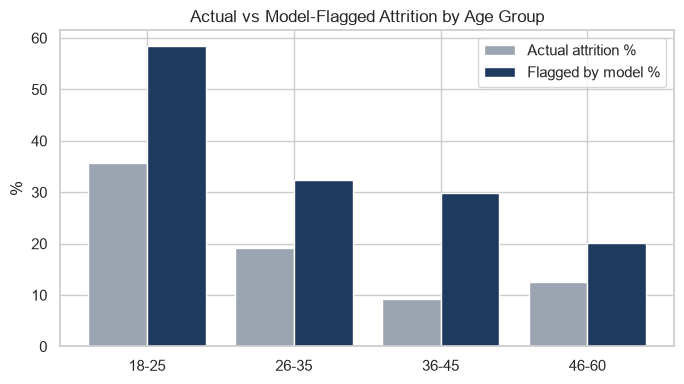

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(age_tbl))
ax.bar(x - 0.2, age_tbl["Actual attrition %"], 0.4, label="Actual attrition %", color=GRAY)
ax.bar(x + 0.2, age_tbl["Flagged %"], 0.4, label="Flagged by model %", color=BLUE)
ax.set_xticks(x)
ax.set_xticklabels(age_tbl["AgeGroup"])
ax.set_ylabel("%")
ax.set_title("Actual vs Model-Flagged Attrition by Age Group")
ax.legend()
plt.tight_layout()
plt.savefig("../outputs/charts/07_fairness_age.png", dpi=300)
plt.show()

In [6]:
sens = ["Gender", "Age"] + [c for c in X.columns if c.startswith("MaritalStatus")]
print("Removed:", sens)

def make_pipe():
    return Pipeline([("scaler", StandardScaler()),
                     ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))])

m2 = make_pipe().fit(X_train.drop(columns=sens), y_train)
p2 = m2.predict(X_test.drop(columns=sens))
pr2 = m2.predict_proba(X_test.drop(columns=sens))[:, 1]

p1 = best_model.predict(X_test)
pr1 = best_model.predict_proba(X_test)[:, 1]

cmp = pd.DataFrame({
    "With sensitive features": [roc_auc_score(y_test, pr1), recall_score(y_test, p1),
                                precision_score(y_test, p1), f1_score(y_test, p1)],
    "Without sensitive features": [roc_auc_score(y_test, pr2), recall_score(y_test, p2),
                                   precision_score(y_test, p2), f1_score(y_test, p2)],
}, index=["ROC-AUC", "Recall", "Precision", "F1"]).round(3)
cmp.to_csv("../outputs/tables/sensitive_features_comparison.csv")
cmp

Removed: ['Gender', 'Age', 'MaritalStatus_Married', 'MaritalStatus_Single']


,With sensitive features,Without sensitive features
ROC-AUC,0.798,0.776
Recall,0.617,0.617
Precision,0.345,0.358
F1,0.443,0.453
